# E63: Do fine-tunes built to elicit sit on fewer MLP neurons than those built to teach something new?


## The answer

No. No reading shows elicit on fewer neurons on all the pairs we tried. The update's spread separates the other way on every test, though it does not beat its reference on two. The activation shift sits narrower for elicit on two families and wider on the third. The count of top neurons enough for half the gain separates only on family C. The test has little power: each comparison is one task against one.


## What we were trying to test

A VPD decomposition appears to tell a fine-tune that strengthens something the original model does from one that teaches it something new. If simply counting MLP neurons did the same, nobody would need the decomposition. So we asked whether fine-tunes built to elicit sit on fewer neurons, in any of five senses.

Here "built to elicit" means only how the task was built: its targets are chosen as something the original model already leans towards, though how far varies, about 100-fold between the elicit map and the same-word table. It is not the causal label of `decisions.md` row 112, where elicitation means the behaviour runs through a mechanism the original model already has. None of these pairs has had a causal check.

Nothing was trained. We read 26 saved full-weight fine-tunes of three families, plus one update that learned nothing.

- **Family A, the main pair.** Both tasks map a key word to a value word after a rare marker. The elicit map's values are words the model already ranks 2nd to 20th. The cipher's are words it almost never predicts. Five seeds each at the same update size, so the cipher has learned less. Two seeds of the cipher at its own learned step, so that both have learned the table.
- **Family B.** Key tables again: the same word back against a random word, both at step 10, two seeds each.
- **Family C.** Broad text tasks at step 300: continuing lowercased text against a 500-word cipher, two seeds each.

A neuron is one of the 12288 GELU outputs across the four blocks. The five readings, each with what it is compared against:

- **Spread of the update.** The participation ratio of each neuron's squared weight change $e_i$, $(\sum e_i)^2 / \sum e_i^2$, as a fraction of 12288. It reads 1 if all neurons change equally. An update on 16 neurons reads 0.0013. Compared with the same reading after a random rotation of the neuron index, which says whether the neuron basis is special.
- **Spread of the first gradient.** The same reading on the task's gradient on the fine-tune's first batch at the original weights, because Adam flattens the finished update. Compared with the same batch with its targets shuffled.
- **Rescale share.** The share of the update lying along each neuron's own original weights. It reads 1 for pure rescaling and about 1/768 for a random change.
- **Spread of the activation shift.** The participation ratio of one window's squared fine-tuned minus original activation at the answer position, median over windows. Compared with a Gaussian update of the same norms on the same matrices, and with the rotated value.
- **Top neurons enough for half the gain.** On each window, rank neurons by that window's own shift, and give the top k the fine-tuned activations in an original-model forward pass. The count is log base 2 of the k at which the rise in the target's log probability reaches half of what all neurons give for that state. Compared with a random order of the neurons.

A reading answers yes only if it passes four tests and a guard. Elicit must be the sparser side at matched size, at equal progress and on each other family. Each gap must beat the seed spread and the same gap on the reference. The guard asks that elicit also lies on the sparser side of the reference itself.

One disclosure. While reviewing the code, the reviewer computed the update's spread and its rotated value on all 26 states, before the rules were amended. So that reading's outcome, no yes and elicit denser in every family, was known before the amendments were filed. No other number was read.


## What we expected, and why

- **The spread of the update will not answer yes.** Adam normalises each weight's step, which flattens any update. This was not a blind prediction, as disclosed above.
- **The rescale share will not answer yes.** We had no reason to think a few steps of Adam align with each neuron's existing weights.
- **The count of neurons will separate at matched size and not at equal progress.** The earlier neuron patching on family A, which ranked neurons by their mean shift over all windows, behaved so. That run found 4096 neurons for half the gain on elicit and 12288 on the matched cipher, and the gap went when the cipher had learned as much.
- **The first gradient and the activation shift: no lean.** Both were left open.


## What we observed

### Is the update itself on fewer neurons when built to elicit?


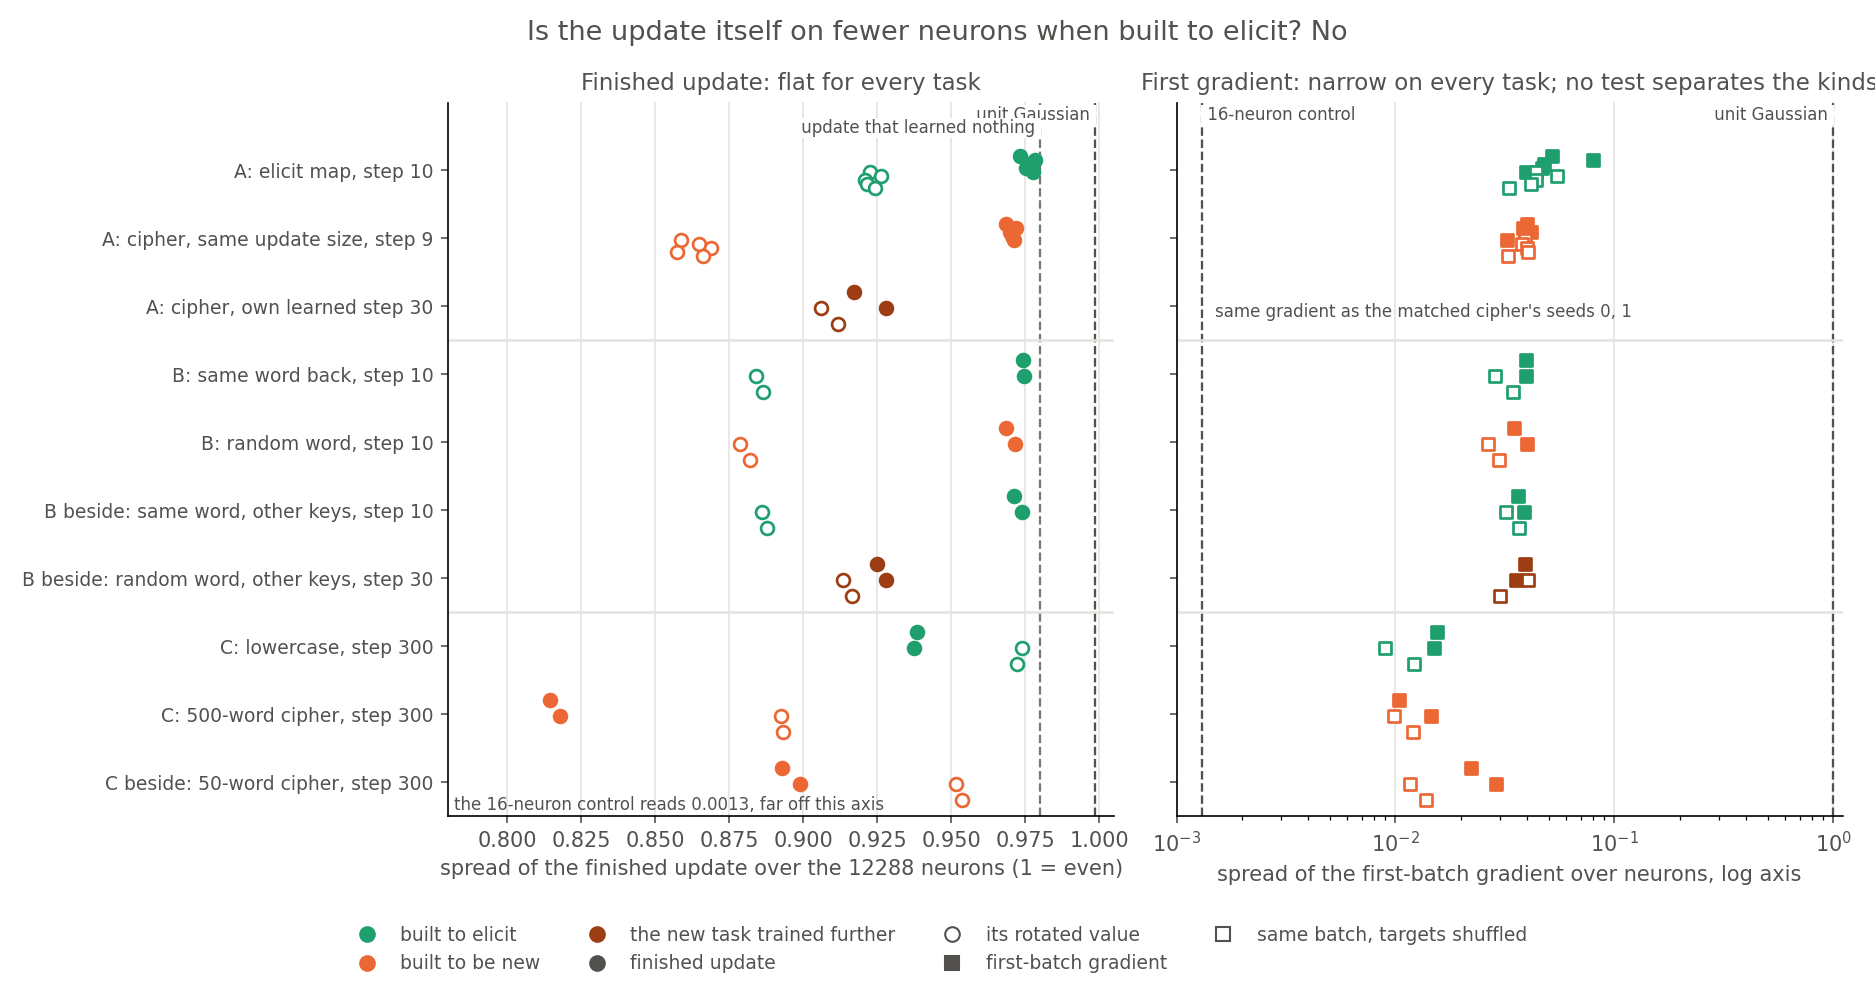

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/neuron_sparsity/figures")
display(Image(filename=str(FIG / "update_sparsity.png")))


**Reading it.** No. The finished update's spread separates the other way on every test, and the first gradient's separates on none, with elicit the higher mean each time. The left panel shows finished updates near 1 on family A, where the elicit map reads 0.976 and the matched cipher 0.970. The 500-word cipher reads lower, 0.816. An update that learned nothing reads 0.980, so being this flat says nothing about the task. Rotating the neuron index narrows the elicit map to 0.923, so on this task the neuron basis is wider than a random basis. The spread falls with training, so its direction need not mean kind. The right panel shows first gradients about twenty times narrower, 0.053 on elicit and 0.038 on the cipher, a gap under the seed spread. Permuting targets within the batch leaves that much the same on family A, 0.043 on elicit. On the 50-word cipher it halves the reading. Adam's flattening remains the filed explanation of the difference between the panels; no SGD fine-tune was run to test it.


### Does the update as a whole lie along the neurons' own weights?


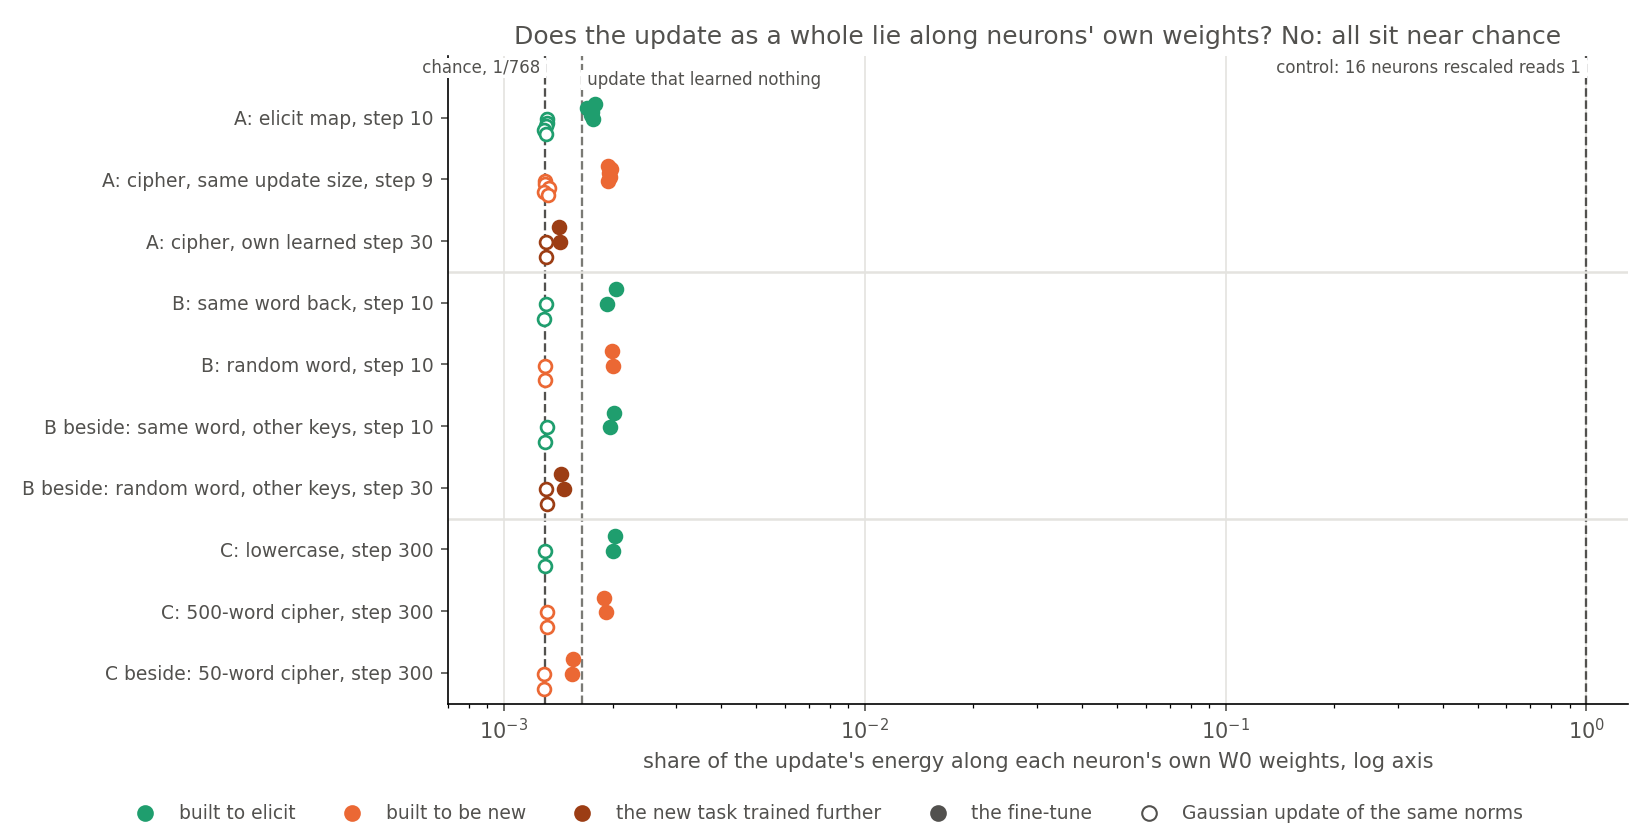

In [2]:
display(Image(filename=str(FIG / "rescale_share.png")))


**Reading it.** No, on any task, though a rescale of a handful of neurons would not show. All the fine-tunes read 0.0014 to 0.0020, next to the Gaussian's 0.0013. The control reads 1 because all its energy sits on 16 rescaled neurons; no control mixes a few into a flat update. On a flat update, the excess over the Gaussian equals only about 5 to 8 fully rescaled neurons. The update that learned nothing has an excess worth 4, so the excess is no evidence of rescaling either. Elicit beats its reference at equal progress and on family C, by at most 0.0003. On family A at matched size the cipher reads higher, 0.0020 against 0.0017. The more trained updates read lower, the cipher 0.0020 at step 9 and 0.0014 at step 30.


### Does the activation shift sit on fewer neurons when built to elicit?


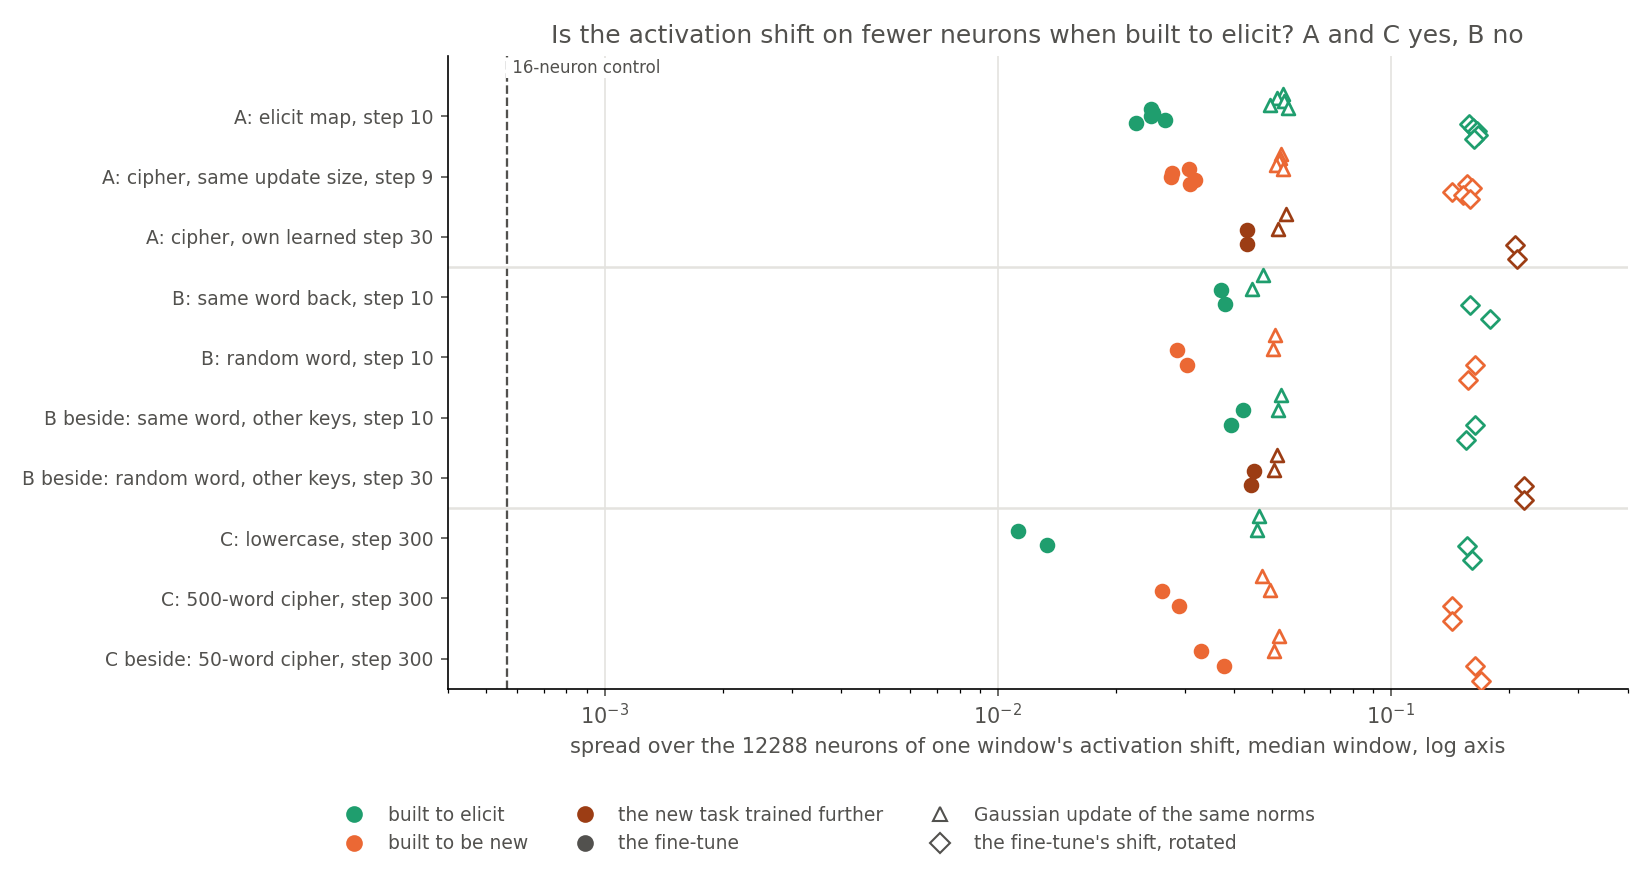

In [3]:
display(Image(filename=str(FIG / "activation_sparsity.png")))


**Reading it.** On families A and C yes; on family B the reverse, and that reversal is what holds this reading's yes back. The elicit map shifts about 300 effective neurons per window and the matched cipher about 370, a gap just over the seed spread. Lowercase shifts about 150 and the broad cipher about 340. On family B the same-word table shifts about 460 and the random table about 360. The gap is wider at the cipher's later step, about 530 neurons, an update twice the size. Elicit was not read there, and a rise on elicit too would shrink it. That equal-progress test fails on the rotated value, which reads only how the shift divides among blocks, not neurons, so that failure is a block effect. Dividing blocks out, in a reading of saved numbers that was not filed, elicit stays narrower on A and C and wider on B. A Gaussian update of the same norms already shifts only about 650 neurons, so a low level alone says little about the fine-tune. The control, an update on 16 neurons, shifts about 7.


### How many top neurons are enough for half the gain on the main pair?


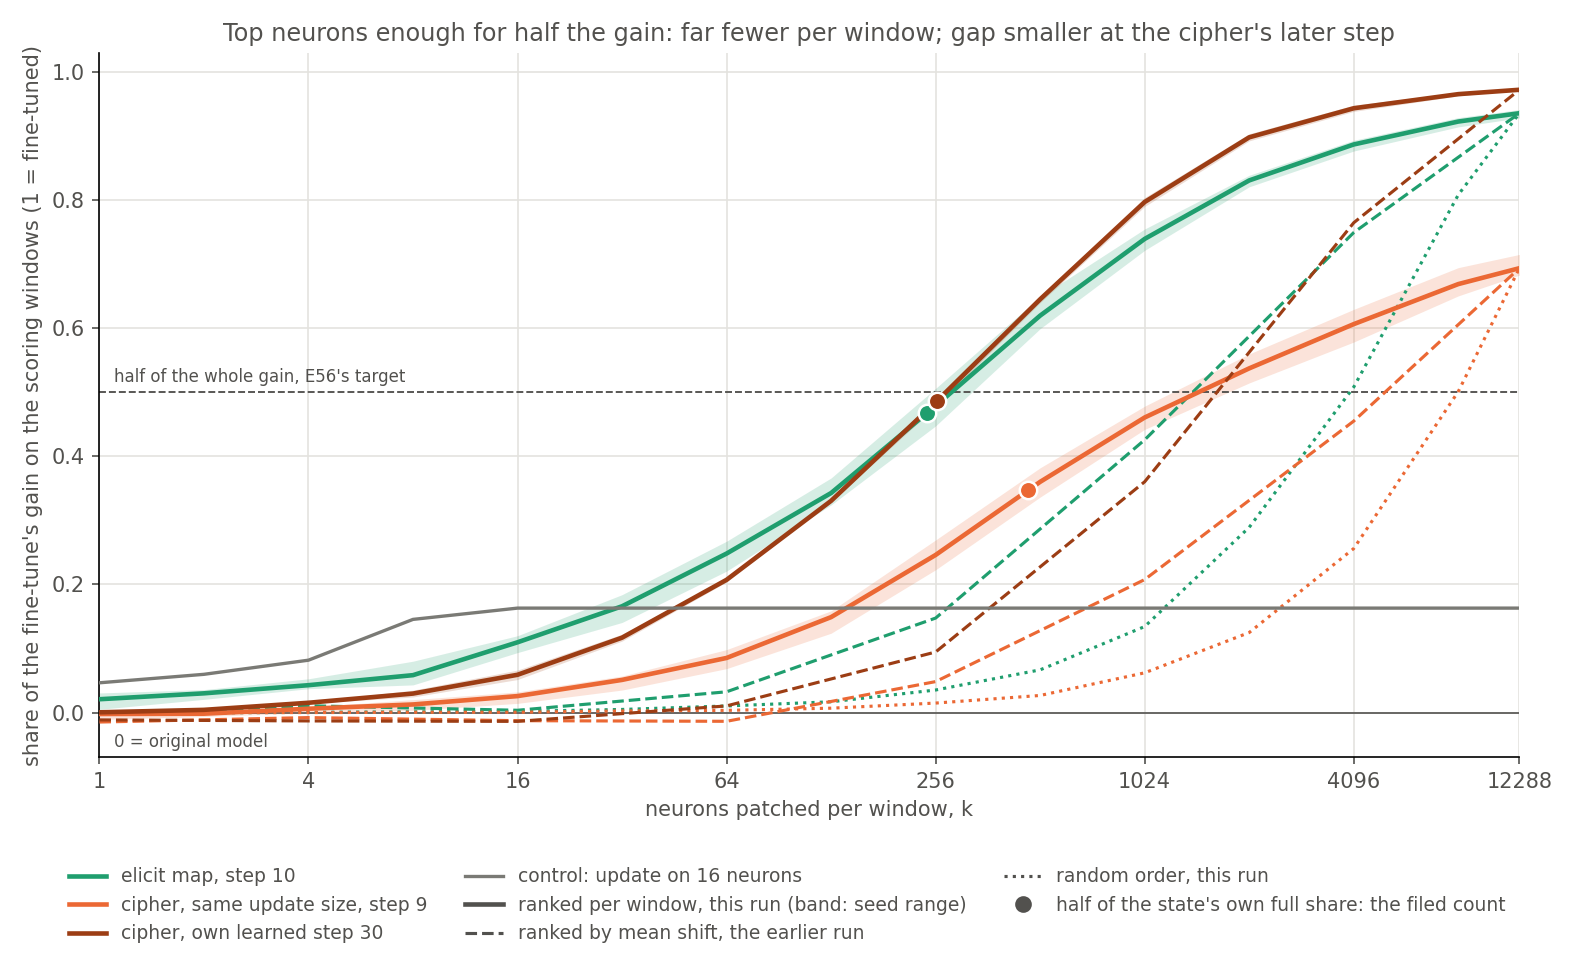

In [4]:
display(Image(filename=str(FIG / "c1_family_a.png")))


**Reading it.** Fewer neurons than the earlier run found, for both kinds, and the gap between kinds misses the filed floor. The top neurons by shift are enough for half of each state's own full share at about 240 on the elicit map and about 470 on the matched cipher. That shows sufficiency under one ranking, not that those neurons are needed. The gap is 0.97 in log base 2, under the filed floor of 1, so by the rule it is noise, though no elicit seed overlaps a cipher seed. At the cipher's own step it is 0.17, about 260 neurons. That step has an update twice the size, and elicit was read at one step only, so progress cannot be told from update size or training length. The control update on 16 neurons reaches its half at about 4, which checks the code, and a random order needs thousands. Solid lines against dashed show what per-window ranking changed. At 256 neurons the elicit map reaches 0.48 of its gain ranked per window, and 0.15 ranked by mean shift. Different keys using different neurons is one reading; per-window ranks following any input-dependent shift is an untested rival. The earlier run's gap was 1.58, on its target of half the whole gain and a coarse grid. On that target, unfiled here, these curves put elicit near 280 and the matched cipher near 1450, a gap of 2.4, which vanishes at the cipher's later step. So the pattern matches the earlier run and the counts are far lower.


### Does the count separate the kinds on the other pairs?


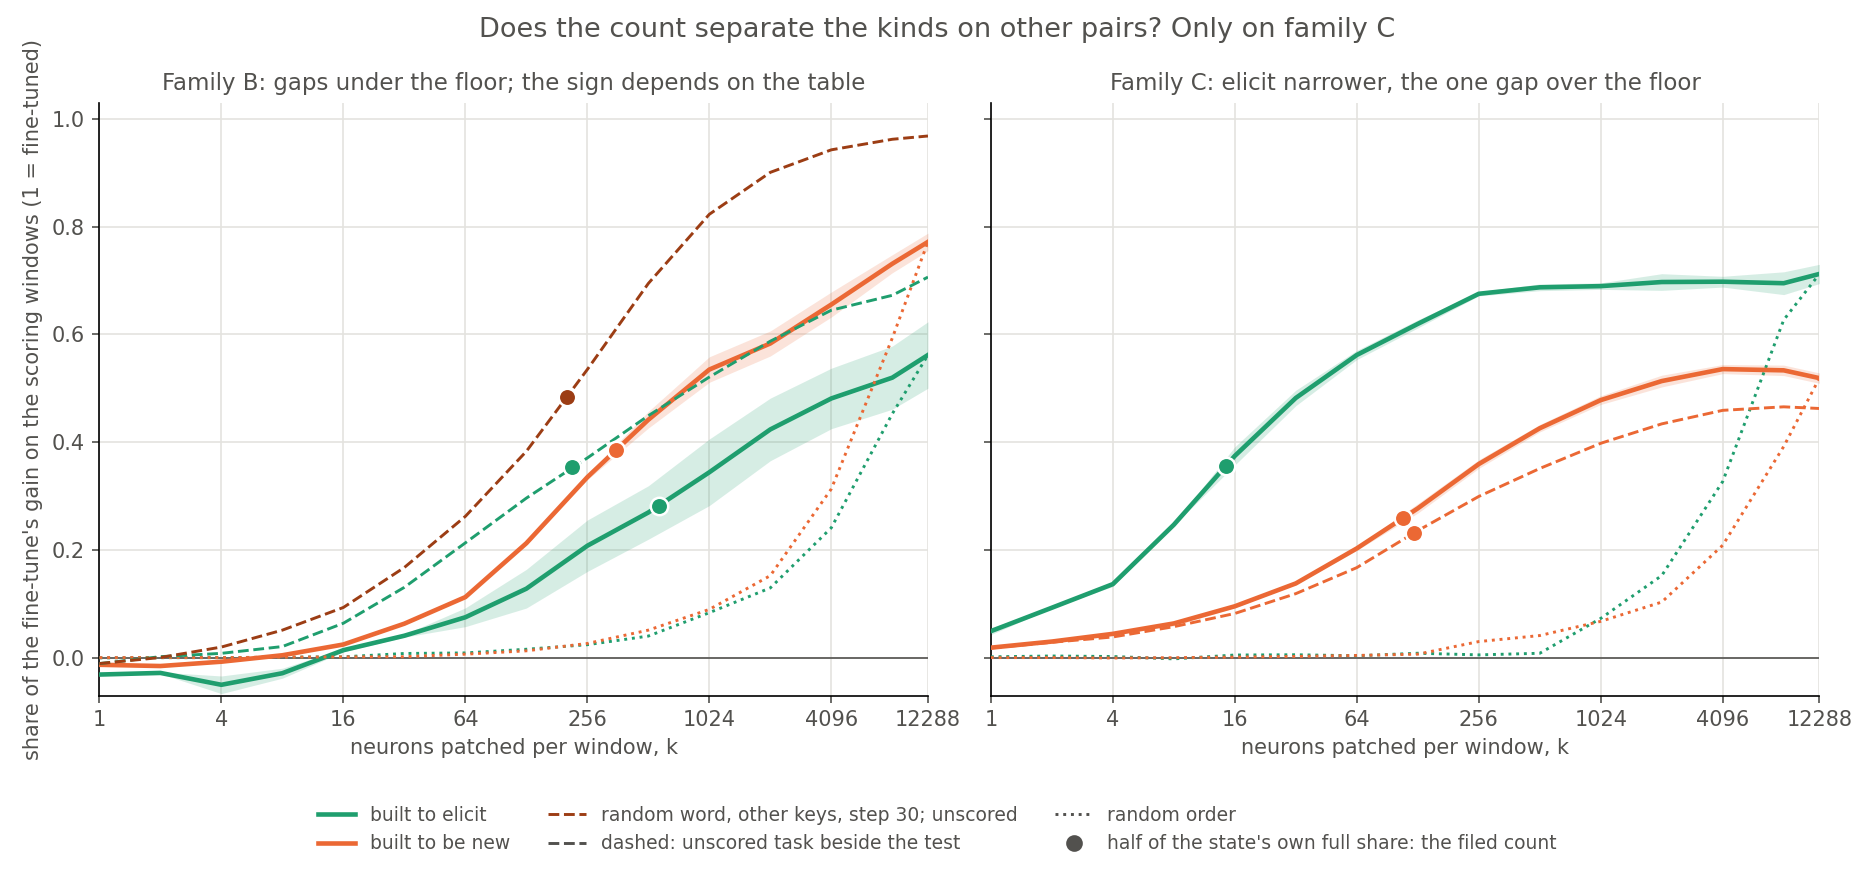

In [5]:
display(Image(filename=str(FIG / "c1_families_bc.png")))


**Reading it.** Only on family C. On family B the scored gap is 0.70 with elicit wider, under the floor. The second same-word table, on other keys, reverses that sign against the same random table, by 0.73. So the sign depends on the table, and two tables built the same way differ by 1.44, more than the kinds do. There is no reversal by this rule. On family C lowercase's top 15 or so are enough for half and the broad cipher's about 110. The 50-word cipher reads about 120, so the two ciphers agree. That pass reads "these tasks differ, in this direction". Lowercase also gains only half what the broad cipher does, and whether that matters was not tested. Counts across families are not like for like, because window lengths and full shares differ.

| family B pair | gap, elicit sparser positive |
|---|---|
| same word against random word, scored | -0.70 |
| same word on other keys against random word, unscored | +0.73 |


## What we learned

Neurons do not map eliciting more cleanly, at this size and on these pairs. Weight updates are no use for this: they are flat and, as a whole, do not lie along existing neurons' weights. Activation shifts differ between tasks by more than seeds, but the direction differs between families.

The decomposition's share of the gain carried by changed CI values does follow the build on the same fine-tunes. This is a reading of saved numbers, not a filed test. It reads 0.76 against 0.25 on family A at matched size, 0.78 against 0.27 on family B, and 0.76 against 0.16 on family C. So none of these neuron numbers is a cheap rival to it in following the build. That does not show the share is right: it has no reference under this rule and no causal check. Since it reads the same-word table like the elicit map, family B's reversal may be about the neuron number and not about that table's label.


## How compelling is the evidence

The controls held, though they exercise the code more than the claims. Rules, tests and verdicts recomputed from the per-state values match the scored file, and an independent check agrees.

What each reading cannot see:

- **Spread of the update:** attention and read-out matrices, and anything Adam's flattening hides.
- **Spread of the first gradient:** later steps, what Adam then does, and progress. On family C it may mostly read ordinary text.
- **Rescale share:** a neuron rotating towards another neuron, and a rescale of a handful of neurons inside a flat update.
- **Spread of the activation shift:** neurons that move and do nothing. Its rotated reference reads block shares only.
- **Top neurons enough for half:** changes to output weights, attention and read-out, all held at the original values; shifts at other positions; and whether those neurons are needed, since no knock-out was run. It also counts per window, so the distinct neurons over all windows are not read.

The largest limit is the design. All four tests compare one task with one task, and seeds barely move these numbers, so almost any two tasks separate and a pass reads "these tasks differ, in this direction". With no kind effect, the sign and separation parts pass about 6-9% per number and 25-37% over five, before the references. The filed 2% and 9% predate family B's change to one task against one. With a kind effect of one task's standard deviation, a number passes only about a third of the time, since one reversed pair fails it. So this null is scoped to these 26 states, three families, the 67M model and Adam fine-tunes, and it is not a measured absence of a kind effect.


## Surprises

No filed prediction reversed. One missed narrowly: the count was filed to pass at matched size, and its gap of 0.97 fell under the floor of 1, with its direction as filed. It is no near-yes, since equal progress and family B fail too.

Three things no prediction covered:

- The activation shift reverses on family B, solidly. The cause is not established.
- Between the cipher's two steps the activation shift spreads while the count falls. Training, update size and progress moved together, and why was not tested.
- On family A the first gradient is about as narrow with targets permuted within the batch. No value had been filed for this.


## What next

- **The truth-set reading needs the user's say.** The tree leaves it open. If the activation shift and the count follow a causal label there, neurons return as a rival.
- **Re-read these numbers on any pair that gets a causal check.** It costs nothing on saved states. If the same-word tables prove not to be eliciting, the shift is the one reading left with a claim.
- **More pairs, and elicit at a later step.** Several tasks per family would turn this no into a measured limit. Elicit past step 10 needs a short new fine-tune, since no such state is saved.


## Scorecard

W1 update spread, W1g first-gradient spread, W2 rescale share, A1 activation-shift spread, C1 top neurons enough for half the gain. T1 family A at matched size, T2 equal progress, T3_B family B, T3_C family C; the guard is elicit against the reference. A test passes only if it separates, elicit is sparser, and it beats the reference's gap. Means are elicit against new.

| number | T1 | T2 | T3_B | T3_C | guard | yes? |
|---|---|---|---|---|---|---|
| W1 | fail 0.976 / 0.970 | fail 0.976 / 0.922 | fail 0.974 / 0.970 | fail 0.938 / 0.816 | fail 0.976 / rotated 0.923 | no |
| W1g | fail 0.053 / 0.038 | fail 0.066 / 0.039 | fail 0.040 / 0.037 | fail 0.015 / 0.012 | fail 0.053 / shuffled 0.043 | no |
| W2 | fail 0.00175 / 0.00196 | **pass** 0.00174 / 0.00143 | fail 0.00199 / 0.00199 | **pass** 0.00202 / 0.00191 | **pass** 0.00175 / Gaussian 0.00131 | no |
| A1 | **pass** 0.0246 / 0.0298 | fail 0.0247 / 0.0430 | fail 0.0375 / 0.0294 | **pass** 0.0123 / 0.0276 | **pass** Gaussian 0.0525, rotated 0.163 | no |
| C1 | fail 7.92 / 8.88 | fail 7.84 / 8.01 | fail 9.18 / 8.48 | **pass** 3.86 / 6.76 | **pass** 7.92 / random 11.82 | no |

| lean | filed | rule | read | verdict |
|---|---|---|---|---|
| P1 | W1 does not answer yes, Adam flattens it | W1 yes is false | false; known before the amendments | right, not blind |
| P2 | W1g unknown | none | fails every test | no lean to score |
| P3 | W2 does not answer yes | W2 yes is false | false | right |
| P4 | A1 unknown | none | passes T1, T3_C, guards; fails T2, T3_B | no lean to score |
| P5 | C1 passes T1, fails T2 | C1 T1 passes and T2 fails | T1 fails, gap 0.965 under floor 1; T2 fails | **missed**, narrowly; not a near-yes |


## Not run

SGD fine-tunes of these pairs, for which the first gradient stands in. Attention-head sparsity. Any new fine-tune. Qwen. The causal label of `decisions.md` row 112, which E64 and E55 pursue. The truth-set reading. The first-gradient reading on task text minus cased rows on family C. The elicit map past step 10, which is not saved. The count of distinct neurons over all windows. Per-block shift shares. The per-neuron rescale share on top-shift neurons. A knock-out of the top neurons. More than one random order per state. r under this rule: its values above are saved numbers.

## Departures from the literature

Neuron patching departs from causal tracing, Meng et al. 2022: fine-tuned activations go into the same input's original-model run at every position, ranked here per window by shift size, read as a share of a gain. The participation ratio is the standard form applied to neuron energies; no paper's procedure was followed. The rotated, shuffled and random-order references, and every threshold, are this project's. Full list in the report.

## Provenance

Report `reports/analyses/2026-11-02_analysis_e63-neuron-sparsity.md`, revised against `reports/reviews/2026-11-02_review_e63-analysis.md`. Results `experiments/neuron_sparsity/results/`. Job 48527, MATS debug QoS, L40, 2 min 12 s, peak 7.5 GB, $0. Code at de14090, unchanged in 5727b38; results committed in 1132c03.
